# NOAA Temperature Time Series Analysis

This notebook analyzes daily temperature observations from `noaa - 5000.csv` using Pandas time series tools. The workflow covers:

1. Converting text dates to datetime objects
2. Aggregating multi-station data and building a DatetimeIndex
3. Resampling to weekly and monthly frequencies
4. Smoothing with a 30-day rolling average
5. Analyzing seasonal patterns by calendar attributes
6. Visualizing daily, rolling, and monthly temperatures

All temperatures are in degrees Fahrenheit (°F).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("noaa - 5000.csv")          # relative path, no C:\Users\...
df["date"] = pd.to_datetime(df["date"])      # str -> datetime64
df = df.sort_values("date")                  # chronological order
df.head()

,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,...,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
3796,242610,99999,2025-01-01,2025,1,1,-28.6,5,-36.0,5,...,*,0.03,E,999.9,0,0,1,0,0,0
1531,422990,99999,2025-01-01,2025,1,1,53.0,4,43.5,4,...,NaN,0.00,I,999.9,0,0,0,0,0,0
1811,431110,99999,2025-01-01,2025,1,1,69.4,4,56.5,4,...,NaN,0.00,I,999.9,0,0,0,0,0,0
2804,679690,99999,2025-01-01,2025,1,1,82.7,4,9999.9,0,...,NaN,0.00,G,999.9,0,1,0,0,1,0
4282,432780,99999,2025-01-01,2025,1,1,79.7,5,74.9,5,...,NaN,0.00,I,999.9,0,0,0,0,0,0


## Step 1: Load Data and Convert Dates

The dataset is loaded with a relative path so the notebook runs on any machine. The `date` column arrives as plain text, so `pd.to_datetime()` converts it to `datetime64`. This lets Pandas understand calendar logic such as time spans, slicing, and resampling. The rows are then sorted chronologically, which time series operations require.

In [2]:
daily = df.groupby("date")["temp"].mean()    # one row per date
daily = daily.asfreq("D")                    # expose missing days as NaN
daily = daily.interpolate()                  # optional: fill gaps (document this in Markdown)

# Date slicing with .loc
july = daily.loc["2025-07"]
q2 = daily.loc["2025-04-01":"2025-06-30"]
display(weekly.head())
display(monthly.head())

NameError: name 'weekly' is not defined

## Step 2: Aggregate Stations and Set a Datetime Index

Several weather stations report on the same date, so I average them with `groupby("date")["temp"].mean()` to get one value per day. This must happen before any rolling or resampling, otherwise the windows would mix duplicate dates.

`asfreq("D")` then creates a complete daily calendar and exposes any missing days as `NaN`. Gaps are filled with linear interpolation. With a DatetimeIndex, I can slice by date strings using `.loc[...]`, for example a single month or a date range.

In [ ]:
weekly = daily.resample("W").mean()
monthly = daily.resample("ME").mean()        # or "MS" for month-start

## Step 3: Resample to Weekly and Monthly Averages

Resampling changes the time interval of the data. Here I downsample the daily means into weekly (`"W"`) and monthly (`"ME"`) averages. It works like a `groupby` built for time intervals, and it reduces day-to-day noise so longer patterns are easier to see.

In [ ]:
roll_30 = daily.rolling(30).mean()

## Step 4: Smooth Noise with a 30-Day Rolling Average

Daily temperatures fluctuate a lot from rapid weather changes. A 30-day rolling mean averages each day with the 29 days before it, producing a smoother curve that highlights the broader trend. The first 29 values are `NaN` because a full 30-day window is not yet available.

In [ ]:
cal = daily.to_frame("temp")
cal["month"] = cal.index.month
cal["day_of_week"] = cal.index.dayofweek     # 0 = Monday

by_month = cal.groupby("month")["temp"].mean()
by_dow = cal.groupby("day_of_week")["temp"].mean()
by_month

month
1    46.684575
2    48.817544
3    55.454227
4    61.440186
5    67.004482
6    66.982261
7    70.408240
8    67.520191
Name: temp, dtype: float64

## Step 5: Calendar Seasonality

The DatetimeIndex provides built-in attributes such as `.month` and `.dayofweek`. I extract them and group the temperatures to compare average conditions by month and by day of the week (0 = Monday, 6 = Sunday). Monthly averages show the seasonal cycle, while day-of-week averages should be roughly flat because weather does not follow the work week.

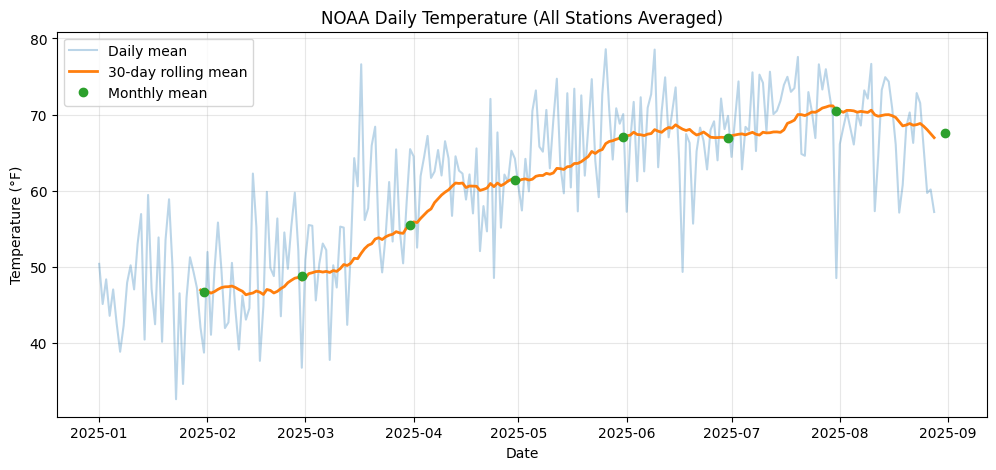

month
1    46.684575
2    48.817544
3    55.454227
4    61.440186
5    67.004482
6    66.982261
7    70.408240
8    67.520191
Name: temp, dtype: float64

day_of_week
0    61.987315
1    60.017329
2    61.016226
3    60.228004
4    59.583245
5    60.834442
6    60.303526
Name: temp, dtype: float64

Missing days: 1
Missing dates: [datetime.date(2025, 8, 25)]
Date range: 2025-01-01 to 2025-08-28
Warmest month: 7 70.4
Coldest month: 1 46.7
Seasonal swing: 23.7
Weekday spread: 2.4
Rolling mean start: 46.9
Rolling mean end: 67.0


In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(daily.index, daily, alpha=0.3, label="Daily mean")
plt.plot(roll_30.index, roll_30, linewidth=2, label="30-day rolling mean")
plt.plot(monthly.index, monthly, "o", label="Monthly mean")
plt.title("NOAA Daily Temperature (All Stations Averaged)")
plt.xlabel("Date")
plt.ylabel("Temperature (°F)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(by_month)
display(by_dow)

# Working with the required data to fill in values.

# Missing days (check before interpolation)
full = df.groupby("date")["temp"].mean().asfreq("D")
print("Missing days:", full.isna().sum())
print("Missing dates:", list(full[full.isna()].index.date))
print("Date range:", daily.index.min().date(), "to", daily.index.max().date())

# Seasonal extremes
print("Warmest month:", by_month.idxmax(), round(by_month.max(), 1))
print("Coldest month:", by_month.idxmin(), round(by_month.min(), 1))
print("Seasonal swing:", round(by_month.max() - by_month.min(), 1))

# Weekday variation
print("Weekday spread:", round(by_dow.max() - by_dow.min(), 1))

# Rolling trend (last valid value vs. first valid value)
print("Rolling mean start:", round(roll_30.dropna().iloc[0], 1))
print("Rolling mean end:", round(roll_30.dropna().iloc[-1], 1))

## Step 6: Visualize Daily, Rolling, and Monthly Temperatures

The chart overlays three views of the same data: the raw daily mean (light line), the 30-day rolling average (bold line), and the monthly mean (dots). This makes it easy to compare short-term noise against the longer seasonal cycle.

## Conclusions

- **Seasonal pattern:** Among the months in the data (January to August 2025), temperatures were highest in July at about 70.4°F and lowest in January at about 46.7°F, a swing of roughly 23.7°F.
- **Smoothing:** The 30-day rolling average removes most daily spikes. It rises from about 46.9°F at the start of the series to about 67.0°F at the end, with the climb flattening out from May onward. It lags the raw data slightly because it is a trailing window.
- **Resampling:** Weekly averages still show some noise, while monthly averages give the clearest view of the seasonal cycle.
- **Day of week:** Average temperature varied by about 2.4°F across weekdays (highest on Monday at about 62.0°F, lowest on Friday at about 59.6°F). This is small compared to the 23.7°F seasonal swing and most likely reflects random variation in a limited sample rather than a real weekly pattern, since weather does not follow the work week.
- **Data quality:** 1 day (2025-08-25) was missing between Jan 1 and Aug 28, 2025, and was filled by linear interpolation.
- **Limitations:** Averaging across stations treats all stations equally, which may hide regional differences. The dataset covers only January to August, so it does not capture a full annual cycle (for example, the colder months of late fall) or year-over-year trends.